In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
seed = 42
np.random.seed(seed)

In [252]:
def draw_dWs(rho, dt, N=1):

    # draw normals
    N1 = np.random.normal(size=(N))
    N2 = np.random.normal(size=(N))

    # setup BMs
    dW1 = np.sqrt(dt) * N1
    dW2 = rho * dW1 + np.sqrt(1-rho**2) * np.sqrt(dt) * N2

    return dW1, dW2

def full_trunc(S0, V0, mu, kappa, theta, sigma_V, rho, Nsteps, N=1, T=1):

    dt = T/Nsteps

    St = S0
    Vt = V0

    # allocate
    V = np.zeros((Nsteps, N)) + np.nan
    S = np.zeros((Nsteps, N)) + np.nan
    X = np.zeros((Nsteps, N)) + np.nan
    X_diff = np.zeros((Nsteps-1, N)) + np.nan
    
    for i in range(Nsteps):

        dW1, dW2 = draw_dWs(rho, dt, N=N)

        # simulate stock price
        Xt = np.log(St)
        Xt = Xt + (mu-0.5*Vt) * dt + np.sqrt(Vt) * dW1
        St = np.exp(Xt)

        # simulate instantenous variance
        Vt = Vt + kappa * (theta - Vt) * dt + sigma_V * np.sqrt(Vt) * dW2
        Vt = np.clip(Vt, 0.00, np.inf)

        # save
        V[i] = Vt
        S[i] = St
        X[i] = Xt

        if i > 0:
            X_diff[i-1] = X[i] - X[i-1]

    return S, V, X, X_diff

# NASDAQ100: Prices and volatility index

In [253]:
SP500_df = pd.read_csv('SP500.csv')
SP500_logreturns_df = np.log(SP500_df['SP500']).diff().dropna()

# load NASDAQ data
NASDAQ100_df = pd.read_csv('NASDAQ100.csv')

# load NASDAQ volatility data
NASDAQ100_vol_df = pd.read_csv('VXNCLS.csv')

# set index to the observation date
for df_ in [NASDAQ100_df, NASDAQ100_vol_df]:
    df_['observation_date'] = pd.DatetimeIndex(df_['observation_date'])
    df_ = NASDAQ100_df.set_index('observation_date')

# merge datasets
df = pd.merge(NASDAQ100_df, NASDAQ100_vol_df, how='left')
df['observation_date'] = pd.DatetimeIndex(df['observation_date'])
df = df.set_index('observation_date')

# compute log-returns
df['log_returns'] = np.log(df['NASDAQ100']).diff()

# drop nans
df = df.dropna()

# Black-Scholes to Heston

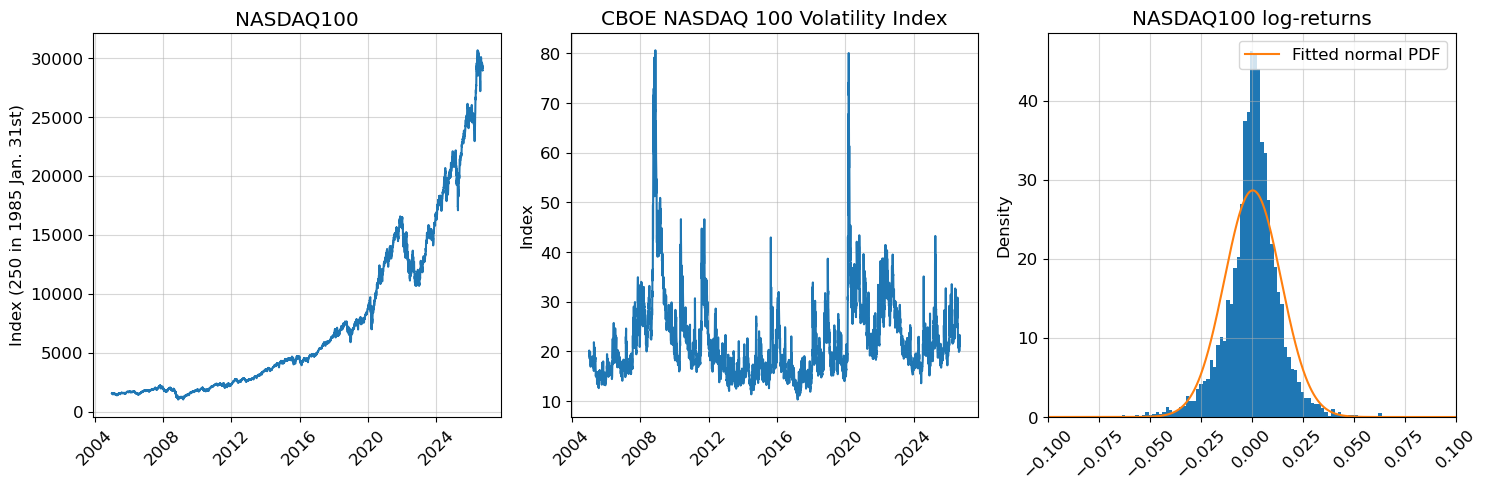

In [257]:
font = { 'size'   : 12}

plt.rc('font', **font)

f, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].plot(df['NASDAQ100'])
ax[0].set_title('NASDAQ100')
ax[0].set_ylabel('Index (250 in 1985 Jan. 31st)')

ax[1].plot(df['VXNCLS'])
ax[1].set_title('CBOE NASDAQ 100 Volatility Index')
ax[1].set_ylabel('Index')

ax[2].hist(df['log_returns'], bins=150, density=True)
ax[2].set_title('NASDAQ100 log-returns')

# fitted normal density
mean = df['log_returns'].mean()
sigma_hat = df['log_returns'].std(ddof=0)

ax[2].plot(np.linspace(df['log_returns'].min(), df['log_returns'].max(), 1000), stats.norm.pdf(np.linspace(df['log_returns'].min(), df['log_returns'].max(), 1000), loc=mean, scale=sigma_hat),
           label='Fitted normal PDF')
ax[2].set_xlim([-0.1, 0.1])
ax[2].set_ylabel('Density')
ax[2].legend()

for i in range(3):
    ax[i].tick_params(axis='x', rotation=45)
    ax[i].grid(alpha=0.5)

f.tight_layout()
f.savefig('BStoHeston_Nasdaq.png')

# Simulating Heston

In [319]:
# unity as 1st stock price
S0 = 1.0

# average Nasdaq drift as trend
mu = df['log_returns'].mean()

theta = 0.04
V0 = theta
kappa = 2
sigma_V = 0.35
rho = -0.5 #np.correlate(V_simple, df['log_returns']).item()
T = 1
Nsteps = 252
N = 100000
dt = T/Nsteps

print(f'Feller is fulfilled: {2*kappa*theta > sigma_V**2}')
print(f'2 kappa theta = {2*kappa*theta}')
print(f'sigma_V^2 = {sigma_V**2}')

Feller is fulfilled: True
2 kappa theta = 0.16
sigma_V^2 = 0.12249999999999998


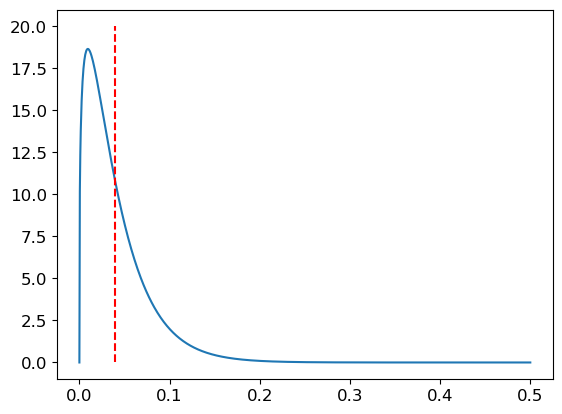

In [320]:
omega_CIR = (2*kappa)/(sigma_V**2)
nu_CIR = (2*kappa*theta)/(sigma_V**2)

shape_Gamma = nu_CIR
scale_Gamma = 1/omega_CIR

x = np.linspace(0,0.5,1000)

plt.plot(x,stats.gamma.pdf(x, a=shape_Gamma, scale=scale_Gamma))
plt.vlines(shape_Gamma*scale_Gamma, 0.00, 20.0, ls='--', color='red')

V_draws = np.random.gamma(shape=shape_Gamma, scale=scale_Gamma, size=(N))
dW1s = np.sqrt(dt) * np.random.normal(size=(N))
dX_draws = (mu-0.5*V_draws)*dt + np.sqrt(V_draws)*dW1s



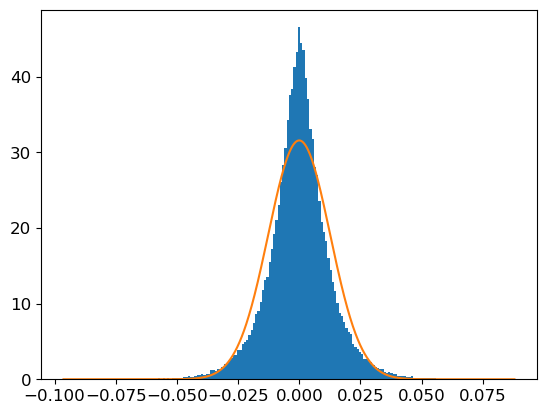

In [321]:
plt.hist(dX_draws, bins=200, density=True)
plt.plot(np.linspace(dX_draws.min(), dX_draws.max(), 1000), stats.norm.pdf(np.linspace(dX_draws.min(), dX_draws.max(), 1000), loc=np.mean(dX_draws), scale=np.std(dX_draws)))

In [301]:
S_sim, V_sim, X_sim, X_diff = full_trunc(S0, V0, mu, kappa, theta, sigma_V, rho, Nsteps, N=N, T=T)

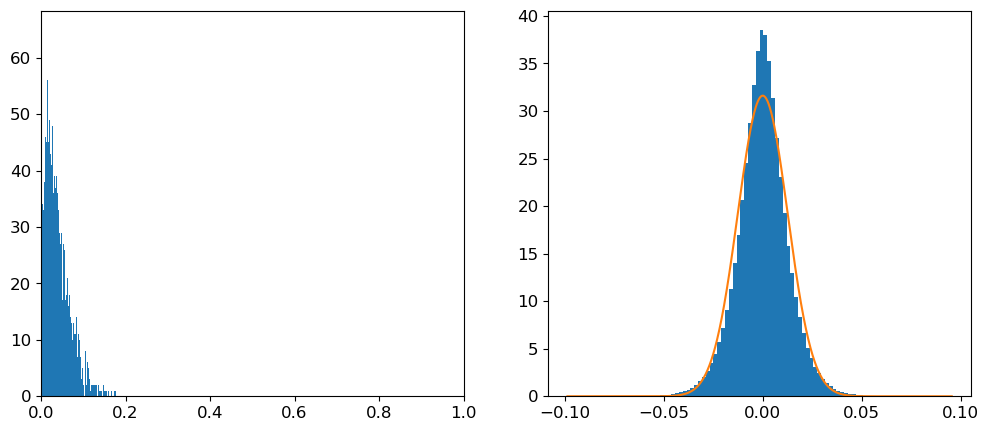

In [302]:
f, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].hist(V_sim[-1,:], bins=1000)
ax[0].set_xlim([0,1])

ax[1].hist(X_diff.flatten(), bins=100, density=True);
ax[1].plot(np.linspace(X_diff.min(), X_diff.max(), 1000),
          stats.norm.pdf(np.linspace(X_diff.min(), X_diff.max(), 1000), loc=X_diff.mean(), scale=X_diff.std()))

In [12]:
(V_sim[-1,:] < 0.01).sum()

np.int64(56929)

In [13]:
# s = T
# t = 0

# c_CIR = (2 * kappa) / ((sigma_V**2)*(1-np.exp(-kappa*(s-t))))
# u_CIR = c_CIR * V0 * np.exp(-kappa*(s-t))
# q_CIR = (2 * kappa * theta) / sigma_V - 1

# nc = 2*u_CIR
# df = 2*q_CIR+2